Imports

In [ ]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import multiprocessing as mp
import pickle

### Car class:

In [ ]:
class VehicleClass:
    def __init__(self, car_id, initial_pos, initial_vel, initial_acc, initial_headway, initial_dv, speedlim, acc_exp, time_gap, min_gap, comf_decel, acc_max, length):

        self.car_id = car_id

        self.pos = [initial_pos]
        self.vel = initial_vel
        self.acc = initial_acc

        self.headway = initial_headway
        self.dv = initial_dv

        self.prev_vel = initial_vel
        self.prev_acc = 0

        self.speedlim = speedlim
        self.des_speed = speedlim
        self.des_speed_inv = 1.0 / speedlim if speedlim > 0 else 0

        self.acc_exp = acc_exp
        self.time_gap = time_gap
        self.min_gap = min_gap
        self.comf_decel = comf_decel
        self.acc_max = acc_max

        self.length = length

    def update_cars(cars, time_step, L):

        # Update acc based on IDM
        acc_new = VehicleClass.calc_acc(cars)

        # Update velocity and position
        cars = VehicleClass.upd_pos_vel(cars, time_step, acc_new, L)

        cars = VehicleClass.update_headway_dv(cars, L, time_step)

        return cars

    def calc_acc(cars):

        acc_new = np.zeros(len(cars))

        for i, car in enumerate(cars):

            # Calculate desired bumper-to-bumper distance (s*)
            s_star = car.min_gap + max(0, car.vel * car.time_gap + (car.vel * car.dv) / (2 * (car.acc_max * car.comf_decel)**0.5))

            # Calculate acceleration using IDM
            acc_new[i] = car.acc_max * (1 - (car.vel * car.des_speed_inv)**car.acc_exp - (s_star / (car.headway))**2)

        # Set new acceleration value
        return acc_new

    def upd_pos_vel(cars, time_step, acc_new, L):

        for i, car in enumerate(cars):

            # Update velocity and position
            vel_new = car.vel + acc_new[i] * time_step

            t = time_step

            # Ensure velocity does not go negative
            if vel_new < 0:

                # Calculate time to stop
                t = -car.vel / acc_new[i]

                vel_new = car.vel + acc_new[i] * t

            pos_new = (car.pos[-1] + car.vel * t + 0.5 * acc_new[i] * t**2) % L

            # Update values
            car.prev_vel = car.vel
            car.prev_acc = acc_new[i]
            car.acc = acc_new[i]
            car.vel = vel_new
            car.pos.append(pos_new)

        return cars

    def update_headway_dv(cars, L, time_step):

        for  i, car in enumerate(cars):

            index = (i + 1) % len(cars)
            next_car = cars[index]

            # Compute headway
            headway = ((next_car.pos[-1] - next_car.length) % L - car.pos[-1]) % L

            if headway < car.min_gap:

                # Calculate desired bumper-to-bumper distance (s*)
                s_star = car.min_gap

                # Calculate acceleration using IDM
                acc_new = car.acc_max * (1 - (car.prev_vel * car.des_speed_inv)**car.acc_exp - (s_star / (headway))**2)

                # Update velocity and position
                vel_new = car.prev_vel + acc_new * time_step

                # Ensure velocity does not go negative
                if vel_new < 0:

                    # Calculate time to stop
                    t_stop = -car.prev_vel / acc_new

                    vel_new = car.prev_vel + acc_new * t_stop

                # Update acceleration and velocity
                car.acc = acc_new
                car.vel = vel_new

        for i, car in enumerate(cars):
            next_car = cars[(i + 1) % len(cars)]
            headway = ((next_car.pos[-1] - next_car.length) % L - car.pos[-1]) % L

            car.headway = headway
            car.dv = car.vel - next_car.vel

        return cars

### Simulation Functions:

In [ ]:
def init_simulation(N, L,):

    cars = []
    initial_vel = 0
    initial_acc = 0
    dv = 0
    length = 5
    min_gap = 2
    acc_exp = 4
    time_gap = 1
    comf_decel = 1.5
    acc_max = 1
    speed_limit = 70 / 2.237

    # Set initial positions
    pos = np.zeros(N)
    for i in range(N):
        pos[i] = i * (length + min_gap)

    # Ensure the minimum gap is maintained
    while True:

        changes = False

        # Loop to adjust positions
        for i in range(N):

            # Next car index
            j = (i + 1) % N

            # Compute headway
            headway = ((pos[j] - length) % L - pos[i]) % L

            # Ensure minimum gap is maintained
            if headway < min_gap:

                changes = True

                # Move the car back to maintain the minimum gap
                pos[i] = ((pos[j] - length) % L - min_gap) % L

        if not changes:
            break

    # Create cars
    for i in range(N - 1):

        next_car = (i + 1) % N
        headway = ((pos[next_car] - length) - pos[i]) % L

        car = VehicleClass(i, pos[i], initial_vel, initial_acc, headway, dv, speed_limit, acc_exp, time_gap, min_gap, comf_decel, acc_max, length)
        cars.append(car)

    print(N, 'Cars initialised')
    return cars

def flow_global(N, velocities, L):

    # Calculate global density (cars per km)
    dens = N / (L / 1000)

    # Calculate avergae velocity
    avg_vel = np.mean(velocities)

    # Calculate global flow (cars per hour)
    flow = dens * avg_vel * 3.6

    return dens, flow

def analyse_global(track_flow, track_dens):

    # Calculate overall global flow and density
    glob_flow = np.mean(track_flow)
    glob_dens = np.mean(track_dens)

    return glob_flow, glob_dens

def analyse_local(track_det_time, track_det_vel, time):

    # Avoid division by zero if no detection data
    if not track_det_time or not track_det_vel:
        return 0, 0

    num_cars = len(track_det_time)

    # Calculate local flow
    loc_flow = (num_cars / time) * 3600

    # Calculate local density
    avg_speed = sum(track_det_vel) / num_cars
    loc_dens = loc_flow / (avg_speed * 3.6)

    return loc_flow, loc_dens

def Step(N, cars, time_pass, time_measure, det_point, L, time_step):

    # Measurement variables
    den = 0
    flo = 0
    detect_time = []
    detect_vel = []

    cars = VehicleClass.update_cars(cars, time_step, L)

    # Take measurements
    if time_pass > time_measure:
        den, flo = flow_global(N, [car.vel for car in cars], L)

        # Detection loop for local measurements
        for i, car in enumerate(cars):

            if (car.pos[-2] < det_point <= car.pos[-1]) or (car.pos[-1] < car.pos[-2] and (car.pos[-2] < det_point <= car.pos[-1] + L)):

                # Calculate distance from initial position to detection point
                s = det_point - car.pos[-2]

                # Calculate delta t
                if car.prev_acc == 0:
                    delta_t = s / car.prev_vel if car.prev_vel != 0 else 0
                else:
                    sqrt_term = car.prev_vel**2 + 2 * car.prev_acc * s
                    delta_t = (-car.prev_vel + np.sqrt(sqrt_term)) / car.prev_acc

                # Store detection time and velocity
                detect_time.append(time_pass - time_step + delta_t)
                detect_vel.append(car.prev_vel + car.prev_acc * delta_t)

    return cars, den, flo, detect_time, detect_vel

def Simulate_IDM(N, time_step, steps, steps_measure, det_point, L):

    # Declare variables
    track_flow = []
    track_dens = []
    track_det_time = []
    track_det_vel = []

    # Initialise cars
    cars = init_simulation(N, L)

    for i in range(steps):

        time_pass = i * time_step

        cars, den, flo, detect_time, detect_vel = Step(N, cars, time_pass, steps_measure * time_step, det_point, L, time_step)

        if time_pass > steps_measure * time_step:
            track_flow.append(flo)
            track_dens.append(den)
            track_det_time.extend(detect_time)
            track_det_vel.extend(detect_vel)

    glob_flow, glob_dens = analyse_global(track_flow, track_dens)
    loc_flow, loc_dens = analyse_local(track_det_time, track_det_vel, steps * time_step)

    print('Simulation for car total', N, 'completed')

    return cars, glob_flow, glob_dens, loc_flow, loc_dens

### Main:

In [ ]:
def run_simulation(N, time_step, steps, steps_before_measure, detection_point, road_length):

    cars, glob_flow, glob_density, loc_flow, loc_dens = Simulate_IDM(N, time_step, steps, steps_before_measure, detection_point, road_length)

    glob_avg_velocity = (glob_flow * 1000) / (glob_density * 3600) if glob_density != 0 else 0
    loc_avg_velocity = (loc_flow * 1000) / (loc_dens * 3600) if loc_dens != 0 else 0

    return N, cars, glob_flow, glob_density, loc_flow, loc_dens, glob_avg_velocity, loc_avg_velocity

if __name__ == "__main__":

    # Model parameters
    max_cars = 60
    road_length = 500
    steps = 10000
    steps_before_measure = 100
    detection_point = road_length / 2
    time_step = 0.5

    # Simulation steps
    start_cars = 2
    end_cars = max_cars
    step_cars = 2

    # List of car counts to simulate
    car_counts = range(start_cars, end_cars + step_cars, step_cars)

    # Run simulations
    with mp.Pool(processes=mp.cpu_count()) as pool:
        results = pool.starmap(run_simulation, [(N, time_step, steps, steps_before_measure, detection_point, road_length) for N in car_counts])

    # Write data to file
    print("Writing file...")

    global_flow, local_flow = [], []
    global_density, local_density = [], []
    global_average_velocity, local_average_velocity = [], []
    cars_positions = []

    for _, car_list, g_flow, g_density, l_flow, l_density, g_avg_vel, l_avg_vel in results:
        global_flow.append(g_flow)
        global_density.append(g_density)
        local_flow.append(l_flow)
        local_density.append(l_density)
        global_average_velocity.append(g_avg_vel)
        local_average_velocity.append(l_avg_vel)
    cars_positions.append([car.pos for car in car_list])

    # Organise data into a dictionary
    simulation_data = {
        "cars_positions": cars_positions,
        "road_length": road_length,
        "global_density": global_density,
        "global_flow": global_flow,
        "local_density": local_density,
        "local_flow": local_flow,
        "global_average_velocity": global_average_velocity,
        "local_average_velocity": local_average_velocity
    }

    # Save using pickle with highest protocol for speed optimisation
    with open('simulation_results_basic_system.pkl', 'wb') as file:
        pickle.dump(simulation_data, file, protocol=pickle.HIGHEST_PROTOCOL)

    print("File writing complete.")

2 10 Cars initialisedCars initialised

Simulation for car total 2 completed
4 Cars initialised
Simulation for car total 4 completed
6 Cars initialised
Simulation for car total 10 completed
12 Cars initialised
Simulation for car total 6 completed
8 Cars initialised
Simulation for car total 12 completed
14 Cars initialised
Simulation for car total 8 completed
18 Cars initialised
Simulation for car total 14 completed
16 Cars initialised
Simulation for car total 18 completed
20 Cars initialised
Simulation for car total 16 completed
Simulation for car total 20 completed
22 Cars initialised
26 Cars initialised
Simulation for car total 22 completed
24 Cars initialised
Simulation for car total 26 completed
28 Cars initialised
Simulation for car total 24 completed
Simulation for car total 28 completed
30 Cars initialised
34 Cars initialised
Simulation for car total 30 completed
32 Cars initialised
Simulation for car total 34 completed
36 Cars initialised
Simulation for car total 32 completed
Si

### Plotting Without Running Simulation:

AttributeError: 'XTick' object has no attribute 'label'

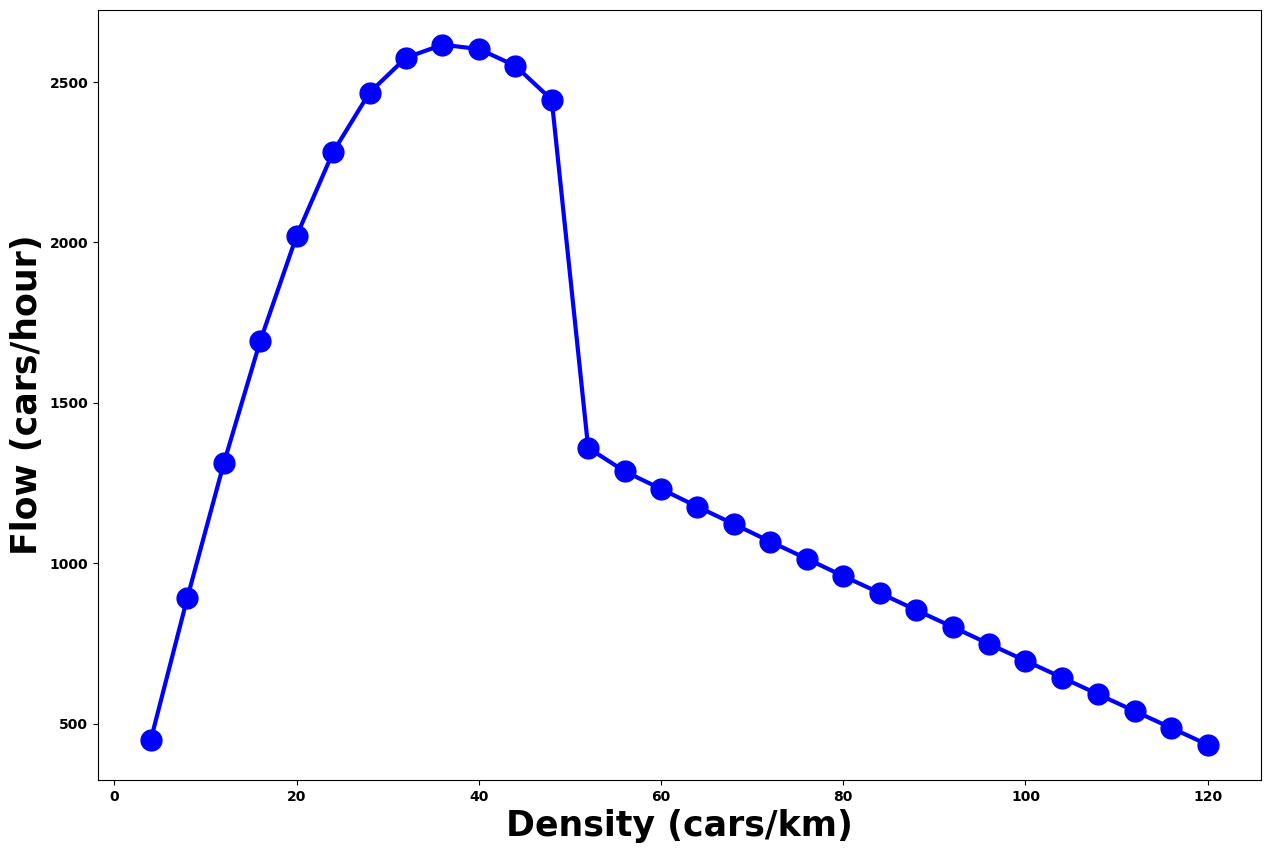

In [ ]:
def load_results(filename):

    with open(filename, 'rb') as file:
        return pickle.load(file)

def plot_graph(ax, x, y, xlabel, ylabel, color, marker='o-'):

    #Plot graph
    ax.plot(x, y, marker, color=color, markersize=15, lw=3)
    ax.set_xlabel(xlabel, fontsize=25, weight='bold')
    ax.set_ylabel(ylabel, fontsize=25, weight='bold')

    for tick in ax.get_xticklabels():
        tick.set_fontweight('bold')
    for tick in ax.get_yticklabels():
        tick.set_fontweight('bold')

    ax.set_xticklabels(ax.get_xticks(), fontsize=25)
    ax.set_yticklabels(ax.get_yticks(), fontsize=25)

    ax.grid()

results = load_results('simulation_results_basic_system.pkl')
data = {key: results.get(key, []) for key in ['cars_positions', 'road_length', 'global_density', 'global_flow', 'local_density', 'local_flow', 'global_average_velocity', 'local_average_velocity']}

# Basic plots
fig1, axes1 = plt.subplots(1, 1, figsize=(15, 10))
plot_graph(axes1, data['global_density'], data['global_flow'], 'Density (cars/km)', 'Flow (cars/hour)', 'blue')
plt.savefig('gfd.png')

fig1, axes1 = plt.subplots(1, 1, figsize=(15, 10))
plot_graph(axes1, data['global_density'], data['global_average_velocity'], 'Density (cars/km)', 'Average Velocity (m/s)', 'blue')
plt.savefig('gvd.png')

fig1, axes1 = plt.subplots(1, 1, figsize=(15, 10))
plot_graph(axes1, data['global_flow'], data['global_average_velocity'], 'Flow (cars/hour)', 'Average Velocity (m/s)', 'blue')
plt.savefig('gvf.png')

fig1, axes1 = plt.subplots(1, 1, figsize=(15, 10))
plot_graph(axes1, data['local_density'], data['local_flow'], 'Density (cars/km)', 'Flow (cars/hour)', 'red')
plt.savefig('lfd.png')

fig1, axes1 = plt.subplots(1, 1, figsize=(15, 10))
plot_graph(axes1, data['local_density'], data['local_average_velocity'], 'Density (cars/km)', 'Average Velocity (m/s)', 'red')
plt.savefig('lvd.png')

fig1, axes1 = plt.subplots(1, 1, figsize=(15, 10))
plot_graph(axes1, data['local_flow'], data['local_average_velocity'], 'Flow (cars/hour)', 'Average Velocity (m/s)', 'red')
plt.savefig('lvf.png')